In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df["species"] = iris.target_names[iris.target]

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
X = df[
    [
        "sepal length (cm)",
        "sepal width (cm)",
        "petal width (cm)"
    ]
]

y = df["petal length (cm)"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(120, 3)
(30, 3)


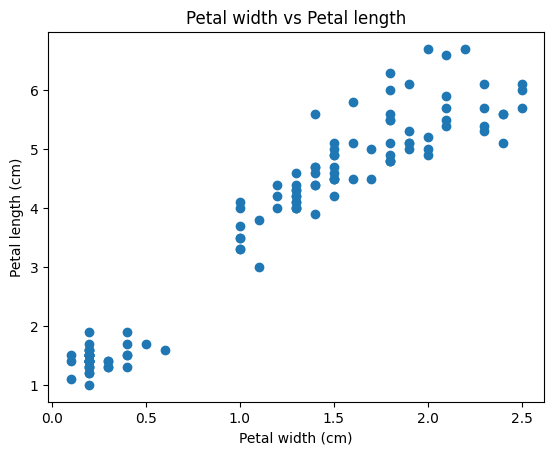

In [5]:
plt.scatter(
    X_train["petal width (cm)"],
    y_train
)

plt.xlabel("Petal width (cm)")
plt.ylabel("Petal length (cm)")
plt.title("Petal width vs Petal length")
plt.show()

y^​=w1​x1​+w2​x2​+w3​x3​+b

In [6]:
model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [ 0.72281463 -0.63581649  1.46752403]
Intercept: -0.26219590258870706


In [7]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 0.26051798462523873
MSE: 0.1300162603138271
RMSE: 0.360577675839516
R2: 0.9603293155857663


In [8]:
results = pd.DataFrame({
    "actual": y_test.values,
    "predicted": y_pred
})

print(results.head(10))

   actual  predicted
0     4.7   4.127716
1     1.7   1.882002
2     6.9   7.025659
3     4.5   4.432110
4     4.8   4.927191
5     1.5   2.066237
6     3.6   3.849479
7     5.1   6.129499
8     4.5   5.021745
9     3.9   3.974453


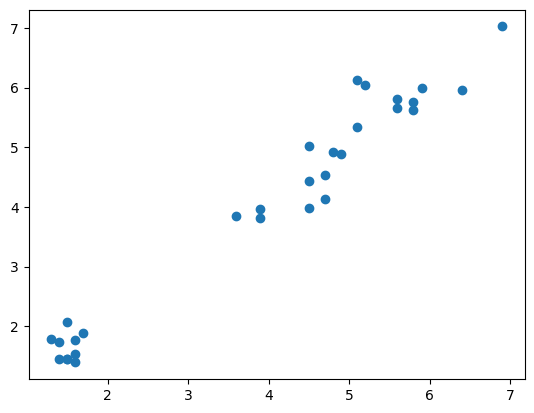

In [16]:
plt.scatter(y_test, y_pred)
plt.show()

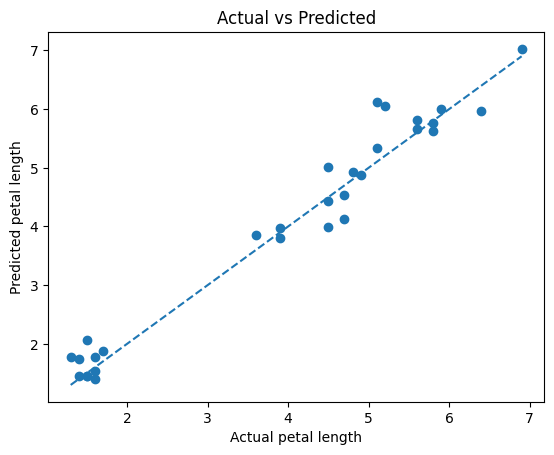

In [9]:
plt.scatter(y_test, y_pred)

plt.xlabel("Actual petal length")
plt.ylabel("Predicted petal length")
plt.title("Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

In [11]:
models = {
    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1, max_iter=10000))
    ])
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    results.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

comparison = pd.DataFrame(results)

print(comparison.round(3))

    model    MAE   RMSE     R2
0  Linear  0.261  0.361  0.960
1   Ridge  0.260  0.359  0.961
2   Lasso  0.280  0.373  0.957


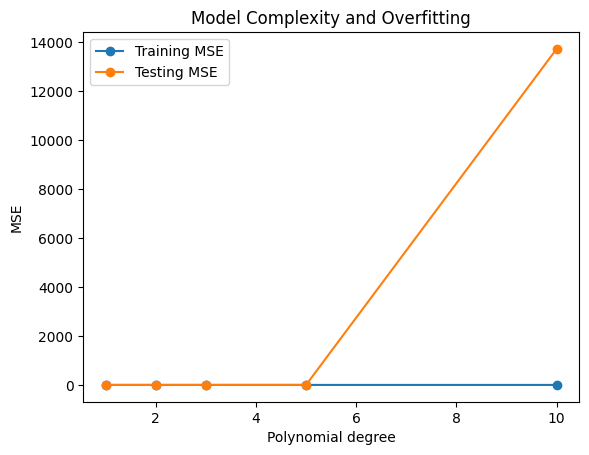

In [12]:
degrees = [1, 2, 3, 5, 10]

train_errors = []
test_errors = []

for degree in degrees:

    model = Pipeline([
        ("poly", PolynomialFeatures(degree=degree)),
        ("scaler", StandardScaler()),
        ("regression", LinearRegression())
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_errors.append(
        mean_squared_error(y_train, train_pred)
    )

    test_errors.append(
        mean_squared_error(y_test, test_pred)
    )

plt.plot(degrees, train_errors, marker="o", label="Training MSE")
plt.plot(degrees, test_errors, marker="o", label="Testing MSE")

plt.xlabel("Polynomial degree")
plt.ylabel("MSE")
plt.title("Model Complexity and Overfitting")
plt.legend()
plt.show()

In [13]:
from sklearn.model_selection import cross_val_score

model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", Ridge(alpha=1.0))
])

scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error"
)

rmse_scores = -scores

print("Fold RMSE:", rmse_scores)
print("Mean RMSE:", rmse_scores.mean())
print("Standard deviation:", rmse_scores.std())

Fold RMSE: [0.27190606 0.30926318 0.36744266 0.28905601 0.30601652]
Mean RMSE: 0.308736887159195
Standard deviation: 0.03224249188538367
